# 03 — Clustering (block B)

**Question of this block.** Without telling the algorithm anything about places or groups, do European cities fall into *types* of air pollution? And if they do, which ones, and what do the types have in common (weather, geography)?

This is **unsupervised** learning: the clusters are built from pollution only, and weather and geography are kept aside to *explain* them afterwards. Every choice — which variables, which distance, which method, how many clusters — is justified, and the result is checked for stability: a clustering always returns clusters, even on data without any structure, so the choices and the stability are what make it a finding. The notebook follows this order:


1. Variables
2. Scale and distance
3. A first look with PCA
4. How many clusters (rule written *before* looking at the result)
5. The clusters: profiles and map
6. A second method (mean-shift) and Ward
7. External validation with weather and geography
8. Robustness: PM2.5, and stations counted once
9. Output and summary

**Input:** `data/processed/cities.csv` (notebook 01), with the shared groups and logarithms of `src/groups.py`.

**Output:** `data/processed/clusters.csv` (one row per city, with its clusters) and figures B1–B5 in `figures/`.

In [1]:
# Libraries, the shared project modules (style, maps, groups) and the table of cities
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MeanShift, AgglomerativeClustering, estimate_bandwidth
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Shared style, maps and groups: the same for the whole project, in src/
sys.path.append("../src")
from style import (apply_style, source, show, CLUSTER_COLOURS, GROUP_ORDER, BLUE, GREY, INK, INK_2, MUTED,
                   DIVERGING_SCALE, DOT_EDGE)
from maps import draw_europe, to_map
from groups import add_groups, add_logs
apply_style()

cities = pd.read_csv("../data/processed/cities.csv")
cities = add_logs(add_groups(cities))      # adds group, po_valley, region and the log_ columns
print(cities.shape)

(284, 36)


**What we see.** 284 cities and 36 columns: the 28 of `cities.csv` plus the three group columns (`region`, `po_valley`, `group`) and the five `log_` columns.

## 1. Which variables

We describe each city by **six pollution variables**: two *levels* and four *shapes* (how pollution changes through the year and the week). Levels alone would only sort cities from clean to dirty; the shapes tell *why* a city is polluted (winter heating, stagnant air, traffic).

<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Variable</th><th style="text-align:left">What it says about a city</th><th style="text-align:left">In the clustering?</th></tr>
<tr><td style="text-align:left"><code>pm10_mean</code></td><td style="text-align:left">how much coarse dust (level)</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>no2_mean</code></td><td style="text-align:left">how much traffic gas (level)</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>o3_peaks</code></td><td style="text-align:left">ozone peaks over the whole year (93rd percentile of the daily 8-hour maximum): photochemical smog, highest in the sunny months</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>log_pm10_winter_summer</code></td><td style="text-align:left">how much PM10 is a winter problem (heating, stagnation); log of a ratio</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>no2_winter_summer</code></td><td style="text-align:left">how much NO₂ is a winter problem</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>no2_weekend_drop</code></td><td style="text-align:left">how much NO₂ falls at the weekend (Saturday and Sunday) compared with weekdays: a traffic fingerprint</td><td style="text-align:left">✔</td></tr>
<tr><td style="text-align:left"><code>pm10_days_above_50</code></td><td style="text-align:left">Spearman 0.90 with PM10: it would count the same thing twice. And the target of block C is built from it: clustering on it and then 'discovering' that a cluster exceeds the limit would be circular</td><td style="text-align:left">✘</td></tr>
<tr><td style="text-align:left"><code>pm25_mean</code>, <code>pm25_pm10_ratio</code></td><td style="text-align:left">missing for 40 cities (notebook 02, section 2): used only in the robustness check of section 8, on the 244 complete cities</td><td style="text-align:left">✘ (check only)</td></tr>
<tr><td style="text-align:left">weather, geography, population</td><td style="text-align:left">they are what we want to <i>explain</i> the clusters with (section 7): if they were inside, the explanation would be circular</td><td style="text-align:left">✘ (validation)</td></tr>
<tr><td style="text-align:left">groups (Po Valley, Poland)</td><td style="text-align:left">descriptive labels, written by us: they must never shape the clusters</td><td style="text-align:left">✘ (comparison only)</td></tr>
</table>

In [2]:
FEATURES = ["pm10_mean", "no2_mean", "o3_peaks", "log_pm10_winter_summer", "no2_winter_summer", "no2_weekend_drop"]

# Short names for the figures
LABELS = {"pm10_mean": "PM10 level", "no2_mean": "NO₂ level", "o3_peaks": "Annual ozone peaks",
          "log_pm10_winter_summer": "PM10 winter/summer", "no2_winter_summer": "NO₂ winter/summer",
          "no2_weekend_drop": "NO₂ weekend decrease"}

print("Missing values in the six variables:", cities[FEATURES].isna().sum().sum())
# How much the six variables overlap (Spearman): if two were almost the same, one would count twice
show(cities[FEATURES].corr(method="spearman").rename(index=LABELS, columns=LABELS))

Missing values in the six variables: 0


,PM10 level,NO₂ level,Annual ozone peaks,PM10 winter/summer,NO₂ winter/summer,NO₂ weekend decrease
PM10 level,1.00,0.40,0.10,0.44,-0.05,-0.24
NO₂ level,0.40,1.00,0.36,0.34,-0.07,-0.29
Annual ozone peaks,0.10,0.36,1.00,0.30,0.33,-0.26
PM10 winter/summer,0.44,0.34,0.30,1.00,0.30,-0.17
NO₂ winter/summer,-0.05,-0.07,0.33,0.30,1.00,0.10
NO₂ weekend decrease,-0.24,-0.29,-0.26,-0.17,0.10,1.00


The count of missing values is 0, so all **284 cities** stay in the clustering. This check is needed: k-means computes distances between cities, and a distance cannot be computed when a value is missing (the city would have to be dropped or its value invented). The overlap is measured with **Spearman** correlation (computed on the ranks of the cities, see notebook 02, section 5.1): several of these variables are skewed, and ranks are not driven by a few extreme cities. The strongest overlaps are PM10 with its winter/summer ratio (0.44) and PM10 with NO₂ (0.40); no pair is close to 1, so each variable adds something.

> ✅ **CHECKPOINT 1 — variables chosen.** Six pollution variables, 284 cities, no missing values. Days above 50 is left out (it repeats PM10 and it is the block C target), PM2.5 only in the check of section 8, weather and geography only to explain.

## 2. Scale and distance

The six variables have different units (µg/m³, ratios, %). k-means groups cities by **Euclidean distance**, so a variable with bigger numbers would count more only because of its unit (ozone, around 110, would beat a ratio around 1.5). We therefore **standardise** each variable: subtract the mean and divide by the standard deviation. After that every variable has mean 0 and standard deviation 1, and "one unit" means "one standard deviation" for all of them: each counts the same.

The PM10 winter/summer ratio enters as a logarithm (`src/groups.py`): its long tail would otherwise let a few cities dominate the distances.

In [3]:
X = StandardScaler().fit_transform(cities[FEATURES])     # each column: mean 0, standard deviation 1
show(pd.DataFrame(X, columns=[LABELS[f] for f in FEATURES]).describe().loc[["mean", "std", "min", "max"]])

,PM10 level,NO₂ level,Annual ozone peaks,PM10 winter/summer,NO₂ winter/summer,NO₂ weekend decrease
mean,0.00,-0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.00,-2.01,-2.65,-2.61,-1.97,-3.16
max,3.41,3.24,3.70,2.79,3.73,4.11


**What we see.** Minimum and maximum are now in standard deviations from the average: the most extreme cities are between about −3 and +4, so no single city is so far away that it would dominate the distances on its own.

> ✅ **CHECKPOINT 2 — data standardised.** Mean 0 and standard deviation 1 for each variable; Euclidean distance on these values.

## 3. A first look: principal components (PCA)

Six dimensions cannot be drawn. PCA finds new axes (combinations of the six variables) that keep as much of the spread between cities as possible. We use it **only to look and to interpret**: k-means works on the six standardised variables, not on the components.

In [4]:
# Explained variance: the share of the differences between cities kept by each component, and the running total
pca = PCA().fit(X)
explained = pd.DataFrame({"explained variance": pca.explained_variance_ratio_,
                          "cumulative": pca.explained_variance_ratio_.cumsum()},
                         index=[f"PC{i + 1}" for i in range(len(FEATURES))])
show(explained)

,explained variance,cumulative
PC1,0.43,0.43
PC2,0.20,0.63
PC3,0.14,0.77
PC4,0.11,0.87
PC5,0.07,0.95
PC6,0.05,1.00


**What we see.** PC1 alone keeps 43% of the differences between cities, far more than the 17% (one sixth) each component would keep if the six variables were unrelated: there is one strong main axis. A single 2D picture (PC1 and PC2) shows 63%.

In [5]:
# Loadings: how much each variable weighs on each component (sign = direction)
loadings = pd.DataFrame(pca.components_[:3].T, index=[LABELS[f] for f in FEATURES], columns=["PC1", "PC2", "PC3"])
show(loadings)

,PC1,PC2,PC3
PM10 level,0.45,-0.25,0.52
NO₂ level,0.44,-0.30,0.05
Annual ozone peaks,0.44,0.30,-0.34
PM10 winter/summer,0.51,0.11,0.27
NO₂ winter/summer,0.23,0.77,-0.09
NO₂ weekend decrease,-0.31,0.40,0.73


- **PC1 (43%) = general pollution level.** All variables push in the same direction except the weekend decrease: polluted cities are polluted in every way and their NO₂ falls less at the weekend (their pollution is not only weekday traffic).
- **PC2 (20%) = NO₂ seasonality and weekend decrease**: cities where NO₂ is a winter and weekday phenomenon.
- The first three components keep **77%** of the spread; we will use them for mean-shift in section 6, which works better in few dimensions.

> ✅ **CHECKPOINT 3 — PCA read.** Two thirds of the differences between cities are "how much" (PC1) and "what kind of NO₂" (PC2).

## 4. How many clusters

### 4.1 The rule, written before looking at the result

<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Criterion</th><th style="text-align:left">What it measures</th><th style="text-align:left">Role</th></tr>
<tr><td style="text-align:left">Elbow (inertia)</td><td style="text-align:left">how much closer the cities get to their centre when we add a cluster</td><td style="text-align:left">hint only: it almost never shows a clear bend</td></tr>
<tr><td style="text-align:left">Silhouette</td><td style="text-align:left">for each city, how much nearer it is to its own cluster than to the next one (−1 to 1)</td><td style="text-align:left">hint</td></tr>
<tr><td style="text-align:left"><b>Bootstrap stability</b></td><td style="text-align:left">redo k-means on 100 resamples of the cities and measure, with the ARI, how much the clusters change (1 = identical). The six variables and their standardisation stay fixed: only the cities are resampled</td><td style="text-align:left"><b>main criterion</b>: a structure that changes when we change the sample is not a finding</td></tr>
<tr><td style="text-align:left">Agreement with mean-shift</td><td style="text-align:left">a different method, which chooses the number of clusters by itself</td><td style="text-align:left">check</td></tr>
<tr><td style="text-align:left">k − 1 and k + 1</td><td style="text-align:left">what changes one step before and after</td><td style="text-align:left">shown for honesty</td></tr>
<tr><td style="text-align:left">Interpretability</td><td style="text-align:left">can each cluster be described in one sentence from its profile?</td><td style="text-align:left">final check</td></tr>
<tr><td style="text-align:left"><s>Matching the Po Valley</s></td><td style="text-align:left">—</td><td style="text-align:left"><b>never used</b>: it would choose k by the answer we expect</td></tr>
</table>

**Method: k-means** with `n_init=50` (50 random starts, the best one is kept, so the result does not depend on a lucky start) and `random_state=0` (same result for everyone who runs the notebook). We try k from 2 to 8.

In [6]:
K_VALUES = range(2, 9)
N_BOOT = 100                      # number of bootstrap resamples
rng = np.random.default_rng(0)    # fixed seed: the resamples are the same at every run

rows, boot_ari = [], {}
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    reference = model.labels_
    # Stability: resample the cities with replacement, refit, assign ALL cities with the new centres,
    # and compare with the reference labels (ARI = 1 means exactly the same partition)
    scores = []
    for b in range(N_BOOT):
        sample = rng.integers(0, len(X), len(X))
        refit = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[sample])
        scores.append(adjusted_rand_score(reference, refit.predict(X)))
    boot_ari[k] = np.array(scores)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X, reference),
                 "stability (median ARI)": np.median(scores), "stability (10th percentile)": np.percentile(scores, 10),
                 "cluster sizes": ", ".join(str(s) for s in sorted(np.bincount(reference), reverse=True))})

choice = pd.DataFrame(rows).set_index("k")
show(choice)

,inertia,silhouette,stability (median ARI),stability (10th percentile),cluster sizes
k,,,,,
2,1245.33,0.40,0.98,0.53,"249, 35"
3,1029.87,0.20,0.75,0.55,"144, 106, 34"
4,895.95,0.22,0.69,0.42,"126, 89, 42, 27"
5,797.39,0.21,0.69,0.44,"81, 78, 56, 42, 27"
6,721.25,0.21,0.70,0.53,"75, 56, 49, 42, 36, 26"
7,675.17,0.20,0.49,0.41,"66, 48, 47, 40, 36, 24, 23"
8,635.44,0.20,0.49,0.42,"62, 43, 36, 36, 35, 26, 24, 22"


**What we see.** The numbers drawn in figure B1, read in section 4.2. The last column, not in the figure, gives the cluster sizes: at k = 2 they are very unbalanced (249 and 35 cities), which matters for Ward in section 6.

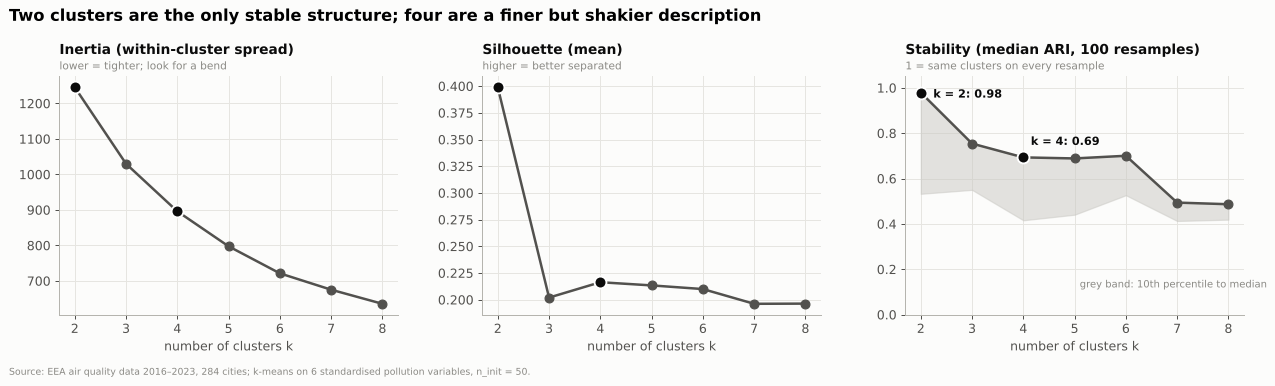

In [7]:
# Figure B1: the three criteria side by side, same x axis (number of clusters)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
ks = list(K_VALUES)
panels = [(axes[0], choice["inertia"], "Inertia (within-cluster spread)", "lower = tighter; look for a bend"),
          (axes[1], choice["silhouette"], "Silhouette (mean)", "higher = better separated"),
          (axes[2], choice["stability (median ARI)"], "Stability (median ARI, 100 resamples)", "1 = same clusters on every resample")]
for ax, values, title, note in panels:
    ax.plot(ks, values, color=INK_2, linewidth=2, marker="o", markersize=7, zorder=2)
    for k_mark in (2, 4):                                    # the two solutions discussed below
        ax.scatter(k_mark, values[k_mark], s=90, color=INK, zorder=3, edgecolor="white", linewidth=1.5)
    ax.set_title(title, fontsize=11, pad=18)
    ax.text(0, 1.03, note, transform=ax.transAxes, fontsize=8.5, color=MUTED)
    ax.set_xticks(ks)
    ax.set_xlabel("number of clusters k")
# Stability: band between the 10th percentile and the median, so the spread of the resamples is visible
axes[2].fill_between(ks, choice["stability (10th percentile)"], choice["stability (median ARI)"], color=GREY, alpha=0.5, zorder=1)
axes[2].set_ylim(0, 1.05)
axes[2].annotate("k = 2: 0.98", (2, choice.loc[2, "stability (median ARI)"]), xytext=(10, -4), textcoords="offset points",
                 fontsize=9, color=INK, fontweight="bold")
axes[2].annotate(f"k = 4: {choice.loc[4, 'stability (median ARI)']:.2f}", (4, choice.loc[4, "stability (median ARI)"]),
                 xytext=(6, 10), textcoords="offset points", fontsize=9, color=INK, fontweight="bold")
axes[2].text(5.1, 0.12, "grey band: 10th percentile to median", fontsize=8, color=MUTED)
fig.suptitle("Two clusters are the only stable structure; four are a finer but shakier description",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.subplots_adjust(left=0.05, right=0.99, top=0.8, bottom=0.17, wspace=0.25)
source(fig, "Source: EEA air quality data 2016–2023, 284 cities; k-means on 6 standardised pollution variables, n_init = 50.")
fig.savefig("../figures/B1_choosing_k.png", bbox_inches="tight")

### 4.2 Reading the three criteria

- **Inertia** goes down smoothly: no clear elbow, as expected (it always falls when k grows).
- **Silhouette** is clearly highest at **k = 2** (0.40); from 3 on it drops to about 0.2, which means weakly separated clusters.
- **Stability** gives the clearest answer: at **k = 2** the median ARI is 0.98 (in two thirds of the resamples the partition is practically identical; section 4.3 shows what moves in the others). From 3 to 6 the median falls to about 0.7, and from 7 on to 0.5.

**Decision, by the rule of 4.1: k = 2 is the main result.** It is the only structure that is both well separated and stable.

**k = 4 is kept as a secondary, finer description**, with its lower stability declared (median ARI 0.69). Why 4 and not 3, 5 or 6, which are just as stable? Because of **interpretability** (last criterion of the rule): at k = 3 the polluted cluster stays almost the same and the other cities split into a clean and a moderate cluster; at k = 4, for the first time, two different polluted profiles appear, each describable in one sentence (section 5.3). k = 4 is a separate, more detailed partition, not a subdivision of the 35 winter-smog cities: one of its polluted clusters also takes in cities that k = 2 puts in the rest (section 5.3). At k = 5 the further split only concerns the moderate cities (section 5.4). This is said openly in the presentation: k = 4 is a *reading aid*, not a discovery as solid as k = 2.

### 4.3 What moves in the unstable resamples

The median stability at k = 2 is 0.98, but the 10th percentile is about 0.5: in some resamples the partition changes a lot. *What* changes? We look at the cities of the small (polluted) cluster in each resample.

In [8]:
reference = KMeans(n_clusters=2, n_init=50, random_state=0).fit_predict(X)
core = reference == np.argmin(np.bincount(reference))          # the 35 cities of the small, polluted cluster
rng_core = np.random.default_rng(0)                             # same resamples as above
rows, left_core = [], []
for b in range(N_BOOT):
    sample = rng_core.integers(0, len(X), len(X))
    labels = KMeans(n_clusters=2, n_init=10, random_state=b).fit(X[sample]).predict(X)
    small = labels == np.argmin(np.bincount(labels))            # the small cluster of this resample
    rows.append({"ARI": adjusted_rand_score(reference, labels), "size of small cluster": small.sum(),
                 "core cities kept (of 35)": (small & core).sum(),
                 "Polish cities added": (small & ~core & (cities["group"] == "Poland")).sum(),
                 "other cities added": (small & ~core & (cities["group"] != "Poland")).sum()})
    left_core += list(cities.loc[core & ~small, "city"])        # core cities that left the small cluster
resamples = pd.DataFrame(rows)
print(f"Resamples with ARI > 0.9: {(resamples['ARI'] > 0.9).sum()} of {N_BOOT}")
print(f"Resamples keeping all 35 core cities together in the small cluster: {(resamples['core cities kept (of 35)'] == 35).sum()} of {N_BOOT}")
print("Core cities that ever left it (number of resamples):", pd.Series(left_core).value_counts().to_dict())
show(resamples.sort_values("ARI").head(8).reset_index(drop=True))

Resamples with ARI > 0.9: 65 of 100
Resamples keeping all 35 core cities together in the small cluster: 81 of 100
Core cities that ever left it (number of resamples): {'Napoli (greater city)': 19, 'Katowice': 6}


,ARI,size of small cluster,core cities kept (of 35),Polish cities added,other cities added
0,0.14,122,35,21,66
1,0.19,111,35,18,58
2,0.29,95,35,19,41
3,0.38,83,35,16,32
4,0.41,79,35,16,28
5,0.43,77,35,18,24
6,0.44,76,35,18,23
7,0.45,75,35,18,22


**The core almost never moves.** In 81 of 100 resamples all 35 cities of the winter-smog cluster stay together; in the others only one or two borderline cities leave (Napoli and Katowice, and nobody else). When stability drops, it is because the small cluster *grows*: in the worst resamples of the table it takes in 16–21 **Polish cities** and 22–66 others. In a typical unstable resample it adds about 17 cities, almost all of them cities that k = 4 will put in their own cluster, "cold-winter particle smog" (mostly Polish); only in the few worst resamples does it grow further into the "moderate" cities. So the uncertain part of k = 2 is its **boundary**, not its core: mainly whether the particle-smog cities (Poland and similar) are "winter smog" or not, which is exactly the cluster that k = 4 separates (cluster 2, section 5.3). Section 8 finds the same boundary from a different direction.

> ✅ **CHECKPOINT 4 — k chosen by the written rule.** k = 2 main (silhouette 0.40, stability 0.98); k = 4 secondary (stability 0.69), chosen among the equally stable k = 3–6 only for interpretability. The groups were not used.

## 5. The clusters

### 5.1 Fit the two solutions and number the clusters

k-means gives arbitrary labels (0, 1, …), which can change between versions of the library. We renumber clusters **by mean PM10, from the most polluted (1) down**, so that "cluster 1" means the same thing for everyone, and colours (fixed order in `src/style.py`) follow the numbers.

In [9]:
def fit_and_number(k):
    # k-means, then renumber clusters 1..k by mean PM10, from the highest down
    labels = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X)
    order = cities.groupby(labels)["pm10_mean"].mean().sort_values(ascending=False).index
    new_number = {old: new for new, old in enumerate(order, start=1)}
    return pd.Series(labels, index=cities.index).map(new_number)

cities["cluster_k2"] = fit_and_number(2)
cities["cluster_k4"] = fit_and_number(4)
show(cities[["cluster_k2", "cluster_k4"]].apply(pd.Series.value_counts).rename_axis("cluster").fillna(0).astype(int))

,cluster_k2,cluster_k4
cluster,,
1,35,27
2,249,42
3,0,126
4,0,89


**What we see.** The number of cities in each cluster: 35 and 249 at k = 2; 27, 42, 126 and 89 at k = 4. Cluster 1 is always the one with the highest mean PM10.

### 5.2 Profiles: what each cluster looks like

For each cluster, the mean of each variable in **standard deviations from the European average** (0 = average city, +1 = one standard deviation above). Colour carries the sign (diverging scale: orange above average, purple below, white at the average); the number in each cell is the mean in **real units**, so the table can be read without the colour.

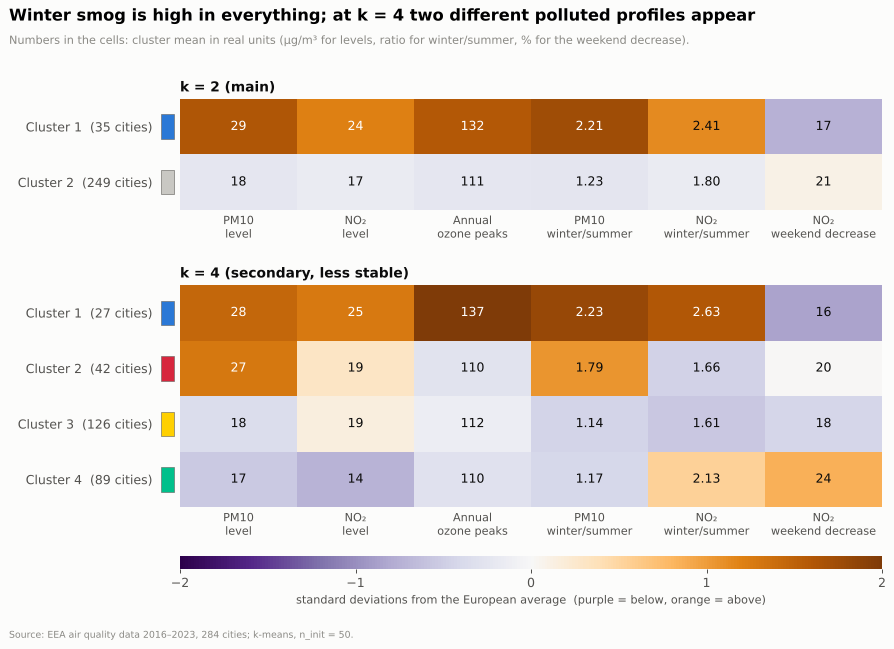

In [10]:
# Figure B2
def profile_table(column):
    z = pd.DataFrame(X, columns=FEATURES).groupby(cities[column]).mean()             # in standard deviations
    real = cities.groupby(column)[FEATURES + ["pm10_winter_summer"]].mean()          # in real units
    real["log_pm10_winter_summer"] = real.pop("pm10_winter_summer")                   # show the ratio, not its log
    return z, real[FEATURES], cities[column].value_counts().sort_index()

def draw_profiles(ax, column, title, colours):
    z, real, sizes = profile_table(column)
    image = ax.imshow(z.values, cmap=DIVERGING_SCALE, vmin=-2, vmax=2, aspect="auto")
    for i in range(z.shape[0]):
        for j, f in enumerate(FEATURES):
            text = f"{real.iloc[i, j]:.2f}" if "winter_summer" in f else f"{real.iloc[i, j]:.0f}"
            ax.text(j, i, text, ha="center", va="center", fontsize=10,
                    color="white" if abs(z.iloc[i, j]) > 1.2 else INK)
    ax.set_xticks(range(len(FEATURES)), [LABELS[f].replace(" ", "\n", 1) for f in FEATURES], fontsize=9)
    ax.set_yticks(range(len(z)), [f"Cluster {c}  ({n} cities)" for c, n in sizes.items()], fontsize=10)
    for i, c in enumerate(sizes.index):          # a square of the cluster colour before each row, as on the map
        ax.add_patch(plt.Rectangle((-0.66, i - 0.22), 0.11, 0.44, color=colours[c - 1], ec=DOT_EDGE, lw=0.5, clip_on=False))
    ax.tick_params(length=0, axis="both"); ax.tick_params(axis="y", pad=22); ax.grid(False)
    for side in ax.spines.values(): side.set_visible(False)
    ax.set_title(title, fontsize=11)
    return image

fig, axes = plt.subplots(2, 1, figsize=(10, 7.2), gridspec_kw={"height_ratios": [2, 4]})
draw_profiles(axes[0], "cluster_k2", "k = 2 (main)", CLUSTER_COLOURS[2])
image = draw_profiles(axes[1], "cluster_k4", "k = 4 (secondary, less stable)", CLUSTER_COLOURS[4])
# Colour bar at the bottom, horizontal, under the tables (label written straight)
bar_axis = fig.add_axes([0.2, 0.115, 0.78, 0.02])          # [left, bottom, width, height] in figure fractions
bar = fig.colorbar(image, cax=bar_axis, orientation="horizontal", ticks=[-2, -1, 0, 1, 2])
bar.set_label("standard deviations from the European average  (purple = below, orange = above)", fontsize=9, color=INK_2)
bar.outline.set_visible(False)
fig.suptitle("Winter smog is high in everything; at k = 4 two different polluted profiles appear",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.925, "Numbers in the cells: cluster mean in real units (µg/m³ for levels, ratio for winter/summer, % for the weekend decrease).",
         fontsize=9, color=MUTED, ha="left")
fig.subplots_adjust(left=0.2, right=0.98, top=0.84, bottom=0.21, hspace=0.45)
source(fig, "Source: EEA air quality data 2016–2023, 284 cities; k-means, n_init = 50.")
fig.savefig("../figures/B2_cluster_profiles.png", bbox_inches="tight")

**What we see.** Each row is a cluster, read across: orange cells are above the European average, purple below. At k = 4 the rows of clusters 1 and 2 look alike for PM10 and differ in the NO₂ columns; section 5.3 turns each row into a name.

In [11]:
# Which cities: the five most polluted of each cluster (k = 4), and where Milan is
for c in range(1, 5):
    members = cities[cities["cluster_k4"] == c].sort_values("pm10_mean", ascending=False)
    countries = members["country"].value_counts().head(4)
    print(f"Cluster {c} ({len(members)} cities) — top PM10: {', '.join(members['city'].head(5))}")
    print(f"           main countries: {', '.join(f'{k} {v}' for k, v in countries.items())}")
milan = cities[cities["city"].str.startswith("Milano")].iloc[0]
print("\nMilan: cluster", milan["cluster_k2"], "at k = 2, cluster", milan["cluster_k4"], "at k = 4")

Cluster 1 (27 cities) — top PM10: Cremona, Padova, Brescia, Vicenza, Treviso
           main countries: IT 27
Cluster 2 (42 cities) — top PM10: Rybnik, Zabrze, Piotrków Trybunalski, Katowice, Granada
           main countries: PL 25, IT 6, CZ 4, ES 2
Cluster 3 (126 cities) — top PM10: Botosani, Athina, Cartagena, Cuenca, Gent
           main countries: DE 49, FR 20, IT 19, ES 11
Cluster 4 (89 cities) — top PM10: Guadalajara, Albacete, Talavera de la Reina, Ciudad Real, Sevilla
           main countries: FR 34, ES 22, DE 7, PL 6

Milan: cluster 1 at k = 2, cluster 1 at k = 4


**What we see.** Cluster 1 (k = 4) is entirely Italian (27 cities, led by Cremona, Padova, Brescia); cluster 2 is led by the Silesian cities (Rybnik, Zabrze, Katowice), with 25 Polish cities out of 42. Milan is in cluster 1 in both solutions.

### 5.3 Names, written from the profiles (not from the map)

**k = 2 (main)**
- **Cluster 1 — "winter smog" (35 cities).** PM10 and NO₂ well above average, PM10 more than twice as high in winter as in summer, high ozone peaks, smaller weekend decrease. Milan is here.
- **Cluster 2 — "the rest of Europe" (249 cities).** Around or below average for everything.

**k = 4 (secondary)**
- **Cluster 1 — "stagnant winter smog".** Highest PM10 *and* highest NO₂, the strongest winter/summer ratios for both, the highest ozone peaks. Every pollutant accumulates: this is what air that does not move looks like.
- **Cluster 2 — "cold-winter particle smog".** PM10 as high as cluster 1 and strongly seasonal, but NO₂ lower and much less seasonal: a winter source of *particles* more than of traffic gas. The name says only what the data show; section 7 shows these are the cities with the coldest winters, which points to heating (in Poland, coal) as the likely source, but we did not measure the source.
- **Cluster 3 — "moderate, flat year".** PM10 near average, NO₂ slightly above, small seasonal changes, small weekend decrease.
- **Cluster 4 — "clean background".** The lowest PM10 and NO₂, the largest weekend decrease (what NO₂ there is comes mostly from weekday traffic).

These two kinds of smog are the same contrast found by eye in notebook 02 (section 6): here it appears **without giving the algorithm any place or group**.

From here on, every table and figure shows the name next to the number of each cluster.

In [12]:
# The names of section 5.3, used from here on in every table and figure
NAMES_K2 = {1: "1  Winter smog", 2: "2  Rest of Europe"}
NAMES_K4 = {1: "1  Stagnant winter smog", 2: "2  Cold-winter particle smog", 3: "3  Moderate, flat year", 4: "4  Clean background"}

# How the two solutions fit together: rows = k = 2, columns = k = 4
nested = pd.crosstab(cities["cluster_k2"].map(NAMES_K2), cities["cluster_k4"].map(NAMES_K4), margins=True, margins_name="total")
show(nested.rename_axis(index="k = 2", columns="k = 4"))

k = 4,1 Stagnant winter smog,2 Cold-winter particle smog,"3 Moderate, flat year",4 Clean background,total
k = 2,,,,,
1 Winter smog,27,8,0,0,35
2 Rest of Europe,0,34,126,89,249
total,27,42,126,89,284


**What we see.** The two solutions are **not simply nested**. "Winter smog" (k = 2, 35 cities) becomes 27 cities of "stagnant winter smog" plus 8 of "cold-winter particle smog". But "cold-winter particle smog" (42 cities) takes only those 8 from winter smog: the other **34 come from "rest of Europe"**. So k = 4 is a different, more detailed partition of all 284 cities, not a split of the 35. What does stay consistent: "stagnant winter smog", "moderate" and "clean" each fall entirely inside one k = 2 cluster, no Po Valley city ends up in a clean cluster, and no clean city in the stagnant smog. The cluster that crosses the boundary is exactly the uncertain boundary found by the bootstrap in section 4.3.

### 5.4 One step before and after (k ± 1)

In [13]:
# k = 3 and k = 5 against k = 4: which clusters merge or split?
cities["cluster_k3"] = fit_and_number(3)
cities["cluster_k5"] = fit_and_number(5)
# k = 3 and k = 5 have no names: their clusters are shown by number only
show(pd.crosstab(cities["cluster_k3"], cities["cluster_k4"].map(NAMES_K4)).rename_axis(index="k = 3", columns="k = 4"))

k = 4,1 Stagnant winter smog,2 Cold-winter particle smog,"3 Moderate, flat year",4 Clean background
k = 3,,,,
1,27,7,0,0
2,0,33,111,0
3,0,2,15,89


In [14]:
show(pd.crosstab(cities["cluster_k4"].map(NAMES_K4), cities["cluster_k5"]).rename_axis(index="k = 4", columns="k = 5"))

k = 5,1,2,3,4,5
k = 4,,,,,
1 Stagnant winter smog,27,0,0,0,0
2 Cold-winter particle smog,0,40,0,2,0
"3 Moderate, flat year",0,2,48,74,2
4 Clean background,0,0,8,2,79


- **k = 3**: the polluted cluster is almost the same as "winter smog" at k = 2 (34 cities: Napoli and Katowice leave, Graz enters); the rest is split into a "clean" and a "moderate" cluster. The two kinds of smog are not separated yet: the first table shows that k = 3 cluster 1 holds all 27 cities of "stagnant winter smog" and only 7 of "cold-winter particle smog".
- **k = 5**: "stagnant winter smog" stays identical (27 cities) and "cold-winter particle smog" almost (40 of 42); what splits is "moderate, flat year" (into 48 and 74 cities). No new profile among the polluted cities.

So k = 4 is the smallest k where the two kinds of smog appear, and k = 5 adds nothing to the story.

### 5.5 Map

The map is drawn **after** the clusters, only to see where they are. Same equal-area projection as figure A1.

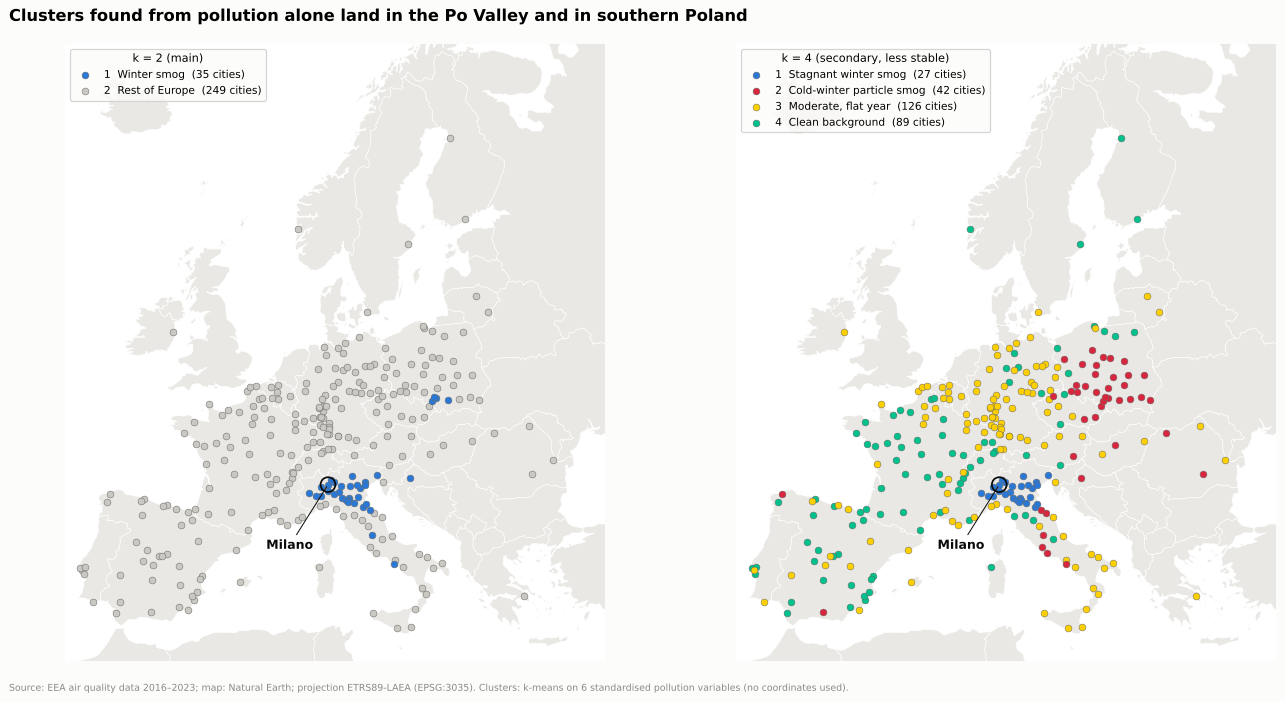

In [15]:
# Figure B3: the clusters on the map of Europe, k = 2 on the left and k = 4 on the right
x, y = to_map(cities["lon"], cities["lat"])
mx, my = to_map(milan["lon"], milan["lat"])

fig, axes = plt.subplots(1, 2, figsize=(15, 7.8))
for ax, column, names, title in [(axes[0], "cluster_k2", NAMES_K2, "k = 2 (main)"),
                                 (axes[1], "cluster_k4", NAMES_K4, "k = 4 (secondary, less stable)")]:
    colours = CLUSTER_COLOURS[len(names)]
    draw_europe(ax)
    for c in sorted(names, reverse=True):                  # cluster 1 drawn last, on top
        chosen = (cities[column] == c).values
        ax.scatter(x[chosen], y[chosen], s=30, color=colours[c - 1], edgecolor=DOT_EDGE, linewidth=0.4,
                   zorder=2 + (len(names) - c) * 0.1, label=f"{names[c]}  ({chosen.sum()} cities)")
    ax.scatter(mx, my, s=140, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=4)
    # Label in the sea (between Provence and Corsica), joined to Milan by a thin line, so it covers no dots
    ax.annotate("Milano", (mx, my), xytext=to_map(6.2, 42.3), ha="center", va="top", fontsize=10, fontweight="bold", color=INK,
                arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8))
    handles, labels_ = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels_[::-1], title=title, loc="upper left", frameon=True, fontsize=8.5, title_fontsize=9)

fig.suptitle("Clusters found from pollution alone land in the Po Valley and in southern Poland",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.05, wspace=0.03)
source(fig, "Source: EEA air quality data 2016–2023; map: Natural Earth; projection ETRS89-LAEA (EPSG:3035). "
            "Clusters: k-means on 6 standardised pollution variables (no coordinates used).")
fig.savefig("../figures/B3_cluster_maps.png", bbox_inches="tight")

**What we see.** At k = 2 the winter-smog cluster covers the Po Valley, five other Italian cities (Lecco, Trento, Udine, Terni, Napoli), Zagreb and four cities of southern Poland. At k = 4 the Po Valley and southern Poland take two different colours, and the clean cluster lies mostly in France and Spain.

In [16]:
# The clusters against the groups of notebook 02 (the groups were NOT used to build the clusters)
show(pd.crosstab(cities["cluster_k2"].map(NAMES_K2), cities["group"])[GROUP_ORDER].rename_axis(index="k = 2"))

group,Po Valley,Poland,Rest of Europe
k = 2,,,
1 Winter smog,25,4,6
2 Rest of Europe,0,28,221


**What we see (k = 2).** Only now the groups enter, and only to compare. Without any coordinate, the winter-smog cluster contains **all 25 Po Valley cities**. Of the 32 Polish cities only 4 are in it, the most polluted of southern Poland, in and around Silesia (Katowice, Kraków, Rybnik, Zabrze); the other 28 are with the rest of Europe. The 6 "other" cities are Lecco, Trento and Udine, just outside the Po Valley rule (an Alpine valley, or another region), and Terni, Napoli and Zagreb: cities outside the plain with the same kind of pollution.

In [17]:
# Same comparison for k = 4
show(pd.crosstab(cities["cluster_k4"].map(NAMES_K4), cities["group"])[GROUP_ORDER].rename_axis(index="k = 4"))

group,Po Valley,Poland,Rest of Europe
k = 4,,,
1 Stagnant winter smog,24,0,3
2 Cold-winter particle smog,1,25,16
"3 Moderate, flat year",0,1,125
4 Clean background,0,6,83


**What we see (k = 4).**
- **Cluster 1 (stagnant smog)** is almost only Po Valley: 24 of 27; the other 3 are Lecco, Trento and Udine, again Po Valley-like cities outside the rule. No Polish city.
- **Cluster 2 (particle smog)** is 60% Polish (25 of 42). The others are mostly cities of central and eastern Europe with cold winters (Ostrava, Brno and two other Czech cities, Budapest, Graz, Zagreb, two Romanian cities), plus five Italian cities outside the Po Valley (Roma, Napoli, Latina, Terni, Pesaro), two Spanish ones (Granada, A Coruña) and one Po Valley city at the edge of the plain, on the coast: Rimini.
- **Poland splits by geography:** the 6 northernmost Polish cities (Gdynia, Gdańsk, Elbląg, Szczecin on or near the Baltic, Olsztyn and Ełk further inland) are in the clean or moderate cluster, together with Zielona Góra in the west; all the other 25, from Bydgoszcz and Warszawa down to the south, are particle smog. "Poland" is a country, not a type of pollution: the centre and the south are smog, the north is not.

**What it means.** The clusters are geographic although no coordinate was used: the two problem areas of Europe come out of the pollution data alone. The Po Valley is one compact type; Poland is not. And every cluster also contains cities outside the groups: a type of pollution is not the same as a place.

> ✅ **CHECKPOINT 5 — clusters described.** k = 2: winter smog (35) vs rest (249), Milan in the first. k = 4: stagnant smog (Po Valley), cold-winter particle smog (mostly Poland), moderate, clean. Names come from the profiles; the match with the groups is checked only afterwards.

## 6. A second method: mean-shift (and Ward)

If the structure is real, a different method should find it. **Mean-shift** does not need k: it moves every point towards the densest area nearby, and the clusters are the density peaks it ends on. Its only parameter is the **bandwidth** (how far "nearby" reaches). We estimate it from the data (`estimate_bandwidth`, quantile 0.2–0.3: the typical distance to the nearest 20–30% of cities) and we try several values. Mean-shift works poorly in many dimensions, so we use the first **three principal components** (77% of the spread, section 3).

In [18]:
pcs = pca.transform(X)[:, :3]
rows = []
for q in [0.2, 0.25, 0.3]:
    bandwidth = estimate_bandwidth(pcs, quantile=q, random_state=0)
    labels = MeanShift(bandwidth=bandwidth).fit_predict(pcs)
    rows.append({"quantile": q, "bandwidth": bandwidth, "clusters found": len(set(labels)),
                 "sizes": ", ".join(str(s) for s in sorted(np.bincount(labels), reverse=True)),
                 "ARI with k-means k = 2": adjusted_rand_score(labels, cities["cluster_k2"]),
                 "ARI with k-means k = 4": adjusted_rand_score(labels, cities["cluster_k4"])})
    if q == 0.25:
        cities["meanshift"] = labels
show(pd.DataFrame(rows).set_index("quantile"))

,bandwidth,clusters found,sizes,ARI with k-means k = 2,ARI with k-means k = 4
quantile,,,,,
0.200000,1.76,2,"251, 33",0.96,0.20
0.250000,1.90,2,"251, 33",0.96,0.20
0.300000,2.03,2,"250, 34",0.98,0.21


- **Mean-shift finds two clusters by itself** for every bandwidth tried, and they are almost the same as k-means k = 2 (ARI about 0.97). A method that does not know k, working on different inputs (3 components instead of 6 variables), lands on the same answer: strong support for k = 2.
- Mean-shift does not find four clusters: one more reason to call k = 4 a secondary description.

In [19]:
# Ward hierarchical clustering (optional check): merges, step by step, the two groups whose fusion increases the spread least
rows = []
for k in (2, 4):
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    rows.append({"k": k, "sizes": ", ".join(str(s) for s in sorted(np.bincount(ward), reverse=True)),
                 "ARI with k-means": adjusted_rand_score(ward, cities[f"cluster_k{k}"])})
show(pd.DataFrame(rows).set_index("k"))

,sizes,ARI with k-means
k,,
2,"212, 72",0.45
4,"147, 65, 39, 33",0.60


In [20]:
# Ward k = 2 against k-means k = 2: does Ward's polluted cluster contain ours?
ward2 = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)
show(pd.crosstab(cities["cluster_k2"].map(NAMES_K2), ward2).rename(columns=lambda c: f"Ward cluster {c}").rename_axis(index="k-means, k = 2", columns=None))

,Ward cluster 0,Ward cluster 1
"k-means, k = 2",,
1 Winter smog,34,1
2 Rest of Europe,38,211


- **Ward** agrees less (ARI 0.45 at k = 2). Ward prefers clusters of similar size, and our structure is very unbalanced (35 vs 249): its polluted cluster has 72 cities instead of 35. The crosstab shows that it *contains 34 of our 35* and adds 38 borderline cities — again, the same uncertain boundary of section 4.3, not a different structure.

> ✅ **CHECKPOINT 6 — second method agrees.** Mean-shift, with no k given, finds the same two clusters (ARI ≈ 0.97). Ward draws a wider boundary around the same core.

## 7. External validation: what the clusters have in common

The clusters were built from pollution only. Now we ask: **do they also differ in weather and geography?** If they do, the types are not arbitrary; they match conditions that can produce them. This is also the bridge to block C.

- **Kruskal–Wallis test** for each variable: do the clusters have different distributions? It uses ranks, so it needs no normality and is not driven by extreme cities.
- We test **15 variables**: with many tests some come out "significant" by chance, so the p-values are corrected with **Benjamini–Hochberg** (false discovery rate 5%).
- A p-value says only *whether* there is a difference; the **effect size** ε² (epsilon squared, from 0 to 1) says *how big*: roughly 0.01 small, 0.08 medium, 0.26 large.
- A significant Kruskal–Wallis test means that **at least one cluster differs** from the others; it does not say which pairs differ. With k = 4 we do not run pairwise tests: the comparisons between specific clusters below (for example "the weakest winter wind") are **descriptive**, based on the medians.

In [21]:
CONTEXT = {"wind_winter": "Wind in winter", "wind": "Wind (year)", "humidity": "Humidity", "temperature": "Temperature",
           "temperature_winter": "Winter temperature", "diurnal_range": "Day–night range", "rain_mm_day": "Rain",
           "solar_radiation": "Solar radiation", "frost_days_year": "Frost days", "mixing_layer_winter_m": "Mixing layer, winter",
           "altitude": "Altitude", "dist_sea_km": "Distance from sea", "lat": "Latitude", "lon": "Longitude",
           "log_population": "Population (log)"}

def kruskal_table(column):
    names = NAMES_K2 if column == "cluster_k2" else NAMES_K4      # cluster names for the column titles
    rows = []
    k = cities[column].nunique()
    n = len(cities)
    for var, name in CONTEXT.items():
        samples = [cities.loc[cities[column] == c, var] for c in sorted(cities[column].unique())]
        h, p = stats.kruskal(*samples)
        rows.append({"variable": name, "H": h, "p": p, "effect size ε²": max(0, (h - k + 1) / (n - k)),
                     **{f"median: {names[c]}": s.median() for c, s in zip(sorted(cities[column].unique()), samples)}})
    table = pd.DataFrame(rows).set_index("variable")
    table["p corrected (BH)"] = stats.false_discovery_control(table["p"], method="bh")   # Benjamini–Hochberg
    table["significant"] = np.where(table["p corrected (BH)"] < 0.05, "yes", "no")
    return table.sort_values("effect size ε²", ascending=False)

validation_k2 = kruskal_table("cluster_k2")
show(validation_k2.drop(columns=["H", "p"]), decimals=3)

,effect size ε²,median: 1 Winter smog,median: 2 Rest of Europe,p corrected (BH),significant
variable,,,,,
Wind in winter,0.185,2.746,4.636,0.000,yes
Wind (year),0.176,2.704,4.059,0.000,yes
Humidity,0.093,71.538,79.026,0.000,yes
Solar radiation,0.030,14.003,12.121,0.008,yes
Temperature,0.028,13.899,10.819,0.008,yes
Longitude,0.023,11.130,8.660,0.016,yes
Latitude,0.022,45.190,48.200,0.016,yes
Day–night range,0.020,9.256,8.794,0.020,yes
Rain,0.017,2.155,1.981,0.026,yes


- **k = 2: winter wind is the strongest difference** (ε² ≈ 0.18, medium to large): median 2.7 m/s in the winter-smog cluster against 4.6 m/s in the rest. After the two wind variables comes humidity (medium). Everything else is significant but small, or not significant at all.
- **Population separates the clusters very little in our sample** (ε² ≈ 0): the winter-smog cluster is not simply "the big cities". The same holds for the winter mixing layer (consistent with notebook 02: with our data it is a weak variable).

In [22]:
# Same test for the four clusters of k = 4
validation_k4 = kruskal_table("cluster_k4")
show(validation_k4.drop(columns=["H", "p"]), decimals=3)

,effect size ε²,median: 1 Stagnant winter smog,median: 2 Cold-winter particle smog,"median: 3 Moderate, flat year",median: 4 Clean background,p corrected (BH),significant
variable,,,,,,,
Longitude,0.292,10.790,18.035,8.995,2.900,0.000,yes
Wind in winter,0.216,2.420,4.843,4.719,4.398,0.000,yes
Wind (year),0.193,2.475,4.198,4.065,3.967,0.000,yes
Winter temperature,0.109,5.558,0.761,3.227,5.212,0.000,yes
Frost days,0.109,35.125,105.375,63.188,47.000,0.000,yes
Humidity,0.101,71.126,78.972,79.026,78.959,0.000,yes
Solar radiation,0.089,14.003,11.066,12.057,13.298,0.000,yes
Distance from sea,0.080,88.200,321.000,161.600,93.900,0.000,yes
Temperature,0.077,14.021,9.468,10.767,12.024,0.000,yes


- **k = 4: the two kinds of smog have different conditions.** The "stagnant winter smog" cluster has by far the weakest winter wind (median 2.4 m/s, all the others 4.4–4.8). The "cold-winter particle smog" cluster has *normal* wind but the coldest winters (median 0.8 °C in winter, about 105 frost days a year, against 35–63 for the others) and lies far inland (median 321 km from the sea). One looks like air that does not move; the other like a strong winter source even with wind, consistent with heating. Both are hypotheses: sources are not in our data.
- **Longitude has the largest effect at k = 4** (ε² 0.29): the clusters have a geography (west → east: clean, moderate, stagnant, particle smog), even though no coordinate was used.
- Many variables are significant only because we have 284 cities: the effect sizes, not the p-values, tell which differences matter.

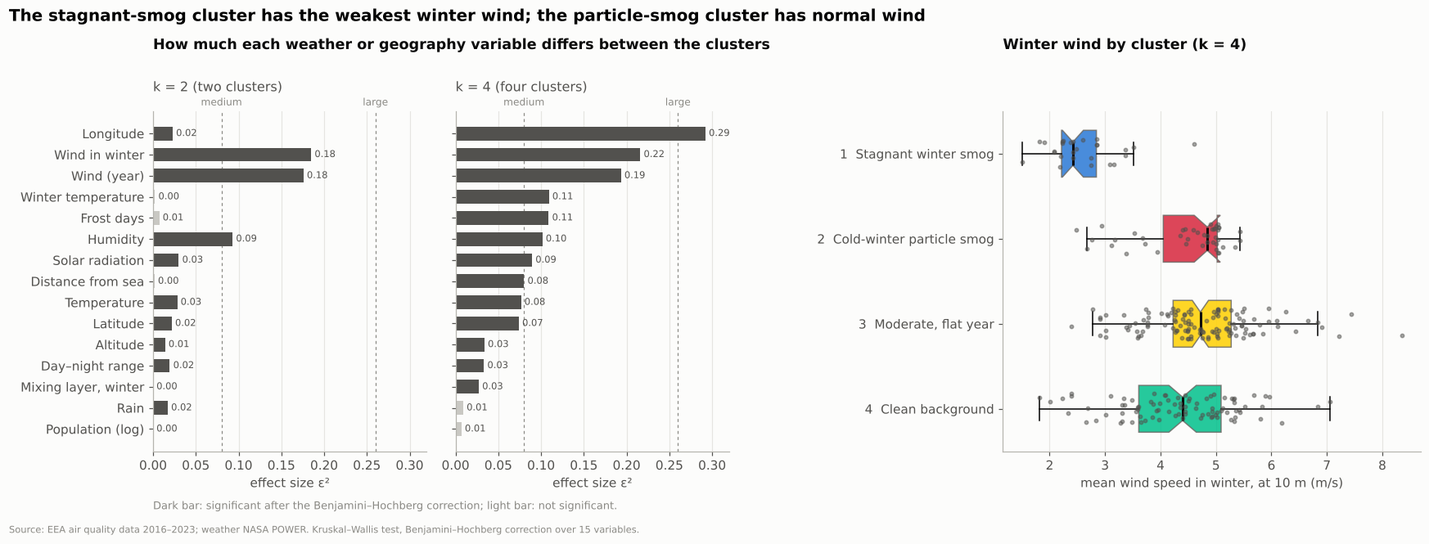

In [23]:
# Figure B4
# Left and centre: one panel per solution (small multiples), same variables in the same order, same x axis.
# Bars start at 0, so their length is the effect size; dark bar = significant after the correction, light bar = not.
fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1, 1.25]})
order = validation_k4.index[::-1]                       # sorted by the effect at k = 4, largest on top
ypos = np.arange(len(order))
for ax, table, title in [(axes[0], validation_k2, "k = 2 (two clusters)"), (axes[1], validation_k4, "k = 4 (four clusters)")]:
    t = table.loc[order]
    significant = (t["significant"] == "yes").values
    ax.barh(ypos, t["effect size ε²"], height=0.65, color=np.where(significant, INK_2, GREY), zorder=2)
    for y, value in zip(ypos, t["effect size ε²"]):                  # value at the end of each bar (also when ≈ 0)
        ax.text(value + 0.004, y, f"{value:.2f}", va="center", fontsize=7.5, color=INK_2, zorder=3)
    for limit, name in [(0.08, "medium"), (0.26, "large")]:          # usual thresholds for ε²
        ax.axvline(limit, color=MUTED, linewidth=0.8, linestyle=(0, (3, 3)), zorder=1)
        ax.text(limit, 1.01, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color=MUTED)
    ax.set_xlim(0, 0.32)
    ax.set_xlabel("effect size ε²")
    ax.set_title(title, fontsize=10.5, fontweight="normal", color=INK_2, pad=16)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, order)
axes[1].set_yticks(ypos, [])                            # same rows as the left panel: no need to repeat the names
fig.text(0.11, 0.905, "How much each weather or geography variable differs between the clusters", fontsize=11.5,
         fontweight="bold", color=INK, ha="left")
axes[0].text(0, -0.17, "Dark bar: significant after the Benjamini–Hochberg correction; light bar: not significant.",
             transform=axes[0].transAxes, fontsize=8.5, color=MUTED)

# Right: winter wind by cluster (k = 4), the strongest stagnation measure of notebook 02
# Notched boxes: where two notches do not overlap, the medians differ (same style as figure A6)
ax = axes[2]
data = [cities.loc[cities["cluster_k4"] == c, "wind_winter"] for c in range(1, 5)]
parts = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False, notch=True,
                   medianprops=dict(color=INK, linewidth=2))
for patch, c in zip(parts["boxes"], range(1, 5)):
    patch.set_facecolor(CLUSTER_COLOURS[4][c - 1]); patch.set_alpha(0.85); patch.set_edgecolor(DOT_EDGE)
for c, values in enumerate(data, start=1):          # every city as a small dot, slightly spread vertically
    ax.scatter(values, c + rng.uniform(-0.18, 0.18, len(values)), s=8, color=INK_2, alpha=0.5, zorder=3)
ax.set_yticks(range(1, 5), [NAMES_K4[c] for c in range(1, 5)])
ax.invert_yaxis()
ax.set_xlabel("mean wind speed in winter, at 10 m (m/s)")
fig.text(0.70, 0.905, "Winter wind by cluster (k = 4)", fontsize=11.5, fontweight="bold", color=INK, ha="left")
ax.grid(axis="y", visible=False)

fig.suptitle("The stagnant-smog cluster has the weakest winter wind; the particle-smog cluster has normal wind",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
# Positions [left, bottom, width, height]: the two bar panels side by side, then room for the cluster names on the right
axes[0].set_position([0.11, 0.16, 0.19, 0.63])
axes[1].set_position([0.32, 0.16, 0.19, 0.63])
axes[2].set_position([0.70, 0.16, 0.29, 0.63])
source(fig, "Source: EEA air quality data 2016–2023; weather NASA POWER. Kruskal–Wallis test, Benjamini–Hochberg correction over 15 variables.")
fig.savefig("../figures/B4_external_validation.png", bbox_inches="tight")

**How to read figure B4.**

*Left and centre: how much each variable differs between the clusters.* Each row is one weather or geography variable; the bar length is its effect size ε², and the number at the end of the bar is its value. The two panels are the two solutions, k = 2 and k = 4, with the same rows in the same order and the same axis, so a variable can be followed from one panel to the other. Dashed lines mark the usual thresholds (0.08 medium, 0.26 large); dark bars are significant after the Benjamini–Hochberg correction, light bars are not.

- **Wind is the variable that matters in both solutions:** winter and yearly wind are the longest bars at k = 2 (0.18), and among the longest at k = 4 (0.22 and 0.19). Humidity is the only other variable of medium size in both (0.09 and 0.10).
- **At k = 4 new variables appear:** winter temperature and frost days go from 0.00–0.01 at k = 2 to 0.11 at k = 4, distance from the sea from 0.00 to 0.08, longitude from 0.02 to 0.29. These are exactly the variables that describe the new cluster, "cold-winter particle smog": cold, inland and eastern. At k = 2 they do not show, because that cluster is split between "winter smog" and "rest of Europe".
- **Two variables separate the clusters very little:** population (0.00 and 0.01) and the winter mixing layer (0.00 and 0.03). In our sample the polluted clusters are not simply "the big cities", and the mixing layer, a rough estimate in our data, adds almost nothing.

*Right: winter wind in each cluster of k = 4.* Each box holds the middle half of the cities of a cluster (from the 25th to the 75th percentile), the black line is the median, the notch around it is a rough 95% interval for the median (where two notches do not overlap, the medians differ), the whiskers reach the cities that are not unusually far from the box, and every grey dot is one city.

- **Only the stagnant-smog cluster is shifted:** median 2.4 m/s, and three quarters of its cities below 2.9 m/s. The other three clusters have medians between 4.4 and 4.8 m/s, and three quarters of their cities above 3.6 m/s: the boxes do not overlap. The notch of the stagnant cluster is far from the other three, whose notches overlap: only stagnant smog has a different median. In the particle-smog box the notch reaches past the edge of the box (it is "folded"), because the median is close to the 75th percentile. Milan, at 2.1 m/s, is in the lower half of its own cluster.
- **The particle-smog cluster has as much wind as the clean cities** (median 4.8 m/s against 4.4): its pollution is not explained by stagnant air.
- **Exceptions are visible:** the dot far to the right of the blue box is Ravenna (4.6 m/s), a coastal city of the plain; on the other side, 14 cities of the other clusters have less than 2.9 m/s of wind without being in the stagnant cluster. Weak wind goes with the Po Valley smog but does not produce it on its own: block C tests how far wind and the other variables can predict it.

In [24]:
# Share of cities over the PM10 exceedance indicator in each cluster. Careful: the limit (35 days > 50 µg/m³) is tied to PM10,
# which is inside the clustering, so this is a description of the clusters, not an independent proof.
for column in ["cluster_k2", "cluster_k4"]:
    table = pd.crosstab(cities[column], cities["exceeds_pm10_limit"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    names = NAMES_K2 if column == "cluster_k2" else NAMES_K4
    print(f"{column}: share over the limit by cluster:",
          ", ".join(f"{names[c]} {s:.0%}" for c, s in cities.groupby(column)["exceeds_pm10_limit"].mean().items()))
    if column == "cluster_k2":
        print(f"           Fisher exact test (2x2): p = {stats.fisher_exact(table)[1]:.1e}")
    print(f"           chi-square = {chi2:.1f}, p = {p:.1e}")

cluster_k2: share over the limit by cluster: 1  Winter smog 69%, 2  Rest of Europe 2%
           Fisher exact test (2x2): p = 4.3e-21
           chi-square = 135.3, p = 2.9e-31
cluster_k4: share over the limit by cluster: 1  Stagnant winter smog 63%, 2  Cold-winter particle smog 31%, 3  Moderate, flat year 0%, 4  Clean background 0%
           chi-square = 122.3, p = 2.4e-26


**Over the limit.** About two thirds of the "winter smog" cities are over the PM10 exceedance indicator (notebook 01, section 5), almost none of the rest. This is expected (PM10 is inside the clustering), so it is a description, not a proof.

**What it does not say.** Kruskal–Wallis compares clusters, it does not show that wind *causes* the pollution; and the clusters are spatially grouped, so nearby cities are not independent observations (the same problem `src/validation.py` handles in block C). The p-values are therefore optimistic; the effect sizes and the direction are the robust part. Block C tests these relations properly, with geographic cross-validation.

> ✅ **CHECKPOINT 7 — clusters validated from outside.** Weather and geography differ between clusters; winter wind is the clearest marker of the stagnant-smog cluster, cold winters of the particle-smog cluster; population separates them very little. Limit exceedance is concentrated in the winter-smog cluster (descriptive).

## 8. Robustness: PM2.5, and stations counted once

40 cities have no PM2.5 (notebook 02, section 2), so PM2.5 was left out. Here we check that this choice does not change the result: on the **244 cities with complete data**, we cluster again **with** PM2.5 and the PM2.5/PM10 ratio (8 variables) and compare with our clusters on the same 244 cities.

In [25]:
complete = cities["pm25_mean"].notna() & cities["pm25_pm10_ratio"].notna()
subset = cities[complete]
print("Cities with PM2.5:", complete.sum(), "| left out:", (~complete).sum(),
      "| left out from the winter-smog cluster:", (~complete & (cities["cluster_k2"] == 1)).sum())

# Four versions, from "same variables, fewer cities" to "all 8 variables", each compared with our clusters on the same cities
versions = {"6 variables (only fewer cities)": [],
            "+ PM2.5/PM10 ratio": ["pm25_pm10_ratio"],
            "+ PM2.5 level": ["pm25_mean"],
            "+ both (8 variables)": ["pm25_mean", "pm25_pm10_ratio"]}
rows = []
for name, extra in versions.items():
    X_sub = StandardScaler().fit_transform(subset[FEATURES + extra])
    row = {"version": name}
    for k in (2, 4):
        labels = pd.Series(KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X_sub), index=subset.index)
        row[f"ARI k = {k}"] = adjusted_rand_score(subset[f"cluster_k{k}"], labels)
        if k == 2:
            # the polluted cluster of this version = the one with the highest mean PM10
            polluted = labels == subset.groupby(labels)["pm10_mean"].mean().idxmax()
            row["polluted cluster: size"] = polluted.sum()
            row["our core kept"] = f"{(polluted & (subset['cluster_k2'] == 1)).sum()} of {(subset['cluster_k2'] == 1).sum()}"
            row["Polish cities in it"] = (polluted & (subset["group"] == "Poland")).sum()
    rows.append(row)
show(pd.DataFrame(rows).set_index("version"))

Cities with PM2.5: 244 | left out: 40 | left out from the winter-smog cluster: 3


,ARI k = 2,polluted cluster: size,our core kept,Polish cities in it,ARI k = 4
version,,,,,
6 variables (only fewer cities),1.00,32,32 of 32,2,0.68
+ PM2.5/PM10 ratio,0.93,33,31 of 32,3,0.56
+ PM2.5 level,0.51,61,32 of 32,21,0.65
+ both (8 variables),0.53,60,32 of 32,21,0.59


Reading the table row by row:

1. **Fewer cities, same variables**: ARI 1.0 at k = 2. Dropping the 40 cities without PM2.5 changes nothing by itself.
2. **Adding the PM2.5/PM10 ratio**: almost no change at k = 2 (ARI 0.93).
3. **Adding the PM2.5 level**: the polluted cluster grows from 32 to about 60 cities, by taking in about 20 **Polish cities**. PM2.5 is strongly tied to PM10 (Spearman 0.83), so it is a second measure of the particle level: particles now count twice, and the cities polluted mainly by particles (Poland) move into the polluted cluster.
4. **Both**: same as 3.

**Conclusion.** The core is robust: with the PM2.5 level, **all 32** of our winter-smog cities (among the 244) stay in the polluted cluster; with the ratio alone, 31 of 32. What changes is again the boundary, and it is the same boundary as in sections 4.3 and 6: whether the Polish (particle-smog) cities belong with the Po Valley or not. Three independent checks (bootstrap, Ward, PM2.5) point at the same uncertainty — which is why k = 4, which gives those cities their own cluster, is a useful reading even if less stable. At k = 4 the ARI is about 0.6–0.7 in every version, *including the first one, without PM2.5*: this is the instability of k = 4 already seen in section 4, not an effect of PM2.5.

**Second check: every station counted once.** In notebook 01 (section 1) some PM10 stations are measured by two sampling points, so they weigh double in the city mean. Here we recompute the two PM10 variables of the clustering (level and winter/summer ratio) counting every station once, and cluster again.

In [26]:
# Recompute the two PM10 variables with every station counted once, then cluster again
cov = pd.read_csv("../data/interim/coverage_pm_station_years.csv")
cov = cov[cov["year"].between(2016, 2023) & (cov["valid_days"] >= 274) & (cov["pollutant"] == "PM10")]
sig = pd.read_csv("../data/interim/signature_pm_station_years.csv")
sig = sig[sig["pollutant"] == "PM10"]

def by_station(table, cols):
    # one row per station and year (two sampling points -> their mean), then per city and year, then per city
    per_station = table.groupby(["country", "city", "eoi", "year"])[cols].mean()
    return per_station.groupby(["country", "city", "year"]).mean().groupby(["country", "city"]).mean()

alt = cities.set_index(["country", "city"])[FEATURES].copy()
alt["pm10_mean"] = by_station(cov, ["mean"])["mean"].reindex(alt.index)
season = by_station(sig, ["mean_winter", "mean_summer"]).reindex(alt.index)
alt["log_pm10_winter_summer"] = np.log(season["mean_winter"] / season["mean_summer"])
X_alt = StandardScaler().fit_transform(alt)
for k in (2, 4):
    labels = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X_alt)
    print(f"k = {k}: ARI with our clusters = {adjusted_rand_score(cities[f'cluster_k{k}'], labels):.2f}")
# Where the cities of k = 4 go (the new clusters are named by letters: their numbers are arbitrary)
moved = pd.crosstab(cities["cluster_k4"].map(NAMES_K4).values, pd.Series(labels).map(dict(enumerate("ABCD"))).values)
show(moved.rename_axis(index="our k = 4", columns="stations counted once"))

k = 2: ARI with our clusters = 1.00
k = 4: ARI with our clusters = 0.89


stations counted once,A,B,C,D
our k = 4,,,,
1 Stagnant winter smog,0,0,0,27
2 Cold-winter particle smog,0,42,0,0
"3 Moderate, flat year",117,0,9,0
4 Clean background,0,0,89,0


**What we see.** k = 2 is identical (ARI 1.00). At k = 4 the two polluted clusters are identical too (27 and 42 cities); only 9 "moderate" cities move to "clean" (ARI 0.89), within the 5–11 cities that already move between these two clusters when only the random seed changes. Counting stations once therefore changes nothing that we report.

> ✅ **CHECKPOINT 8 — robustness to PM2.5 understood.** Dropping cities changes nothing; adding PM2.5 keeps the whole core and widens the polluted cluster to the Polish cities. Our choice (6 variables, 284 cities) keeps Rybnik and Zabrze and does not double-count particles. Counting every station once leaves k = 2 and the two polluted clusters of k = 4 unchanged.

## 9. Output and summary

### 9.1 A picture of the space: the cities on the first two components

The clusters drawn on PC1 (level) and PC2 (NO₂ seasonality), with the arrows of the six variables: the figure that explains, in one image, what separates the clusters.

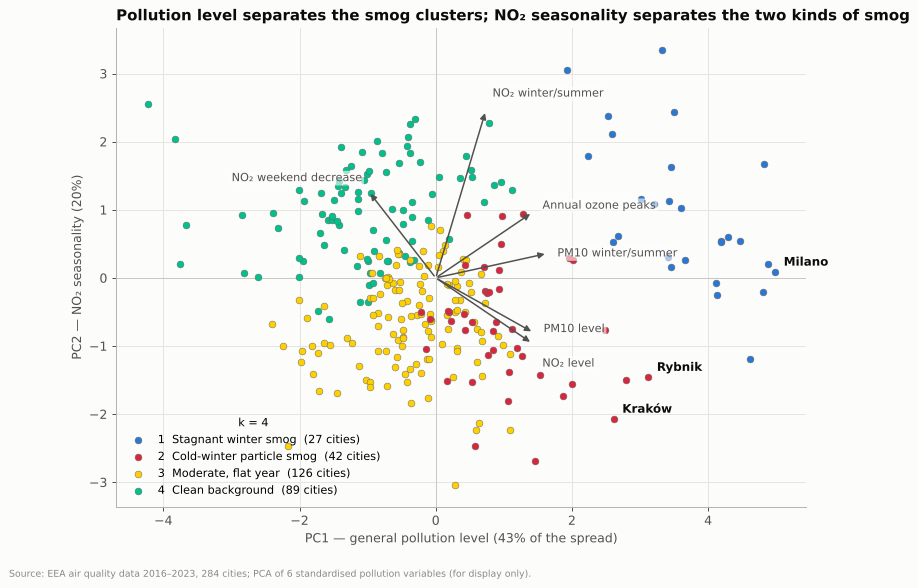

In [27]:
# Figure B5
scores = pca.transform(X)
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(4, 0, -1):
    chosen = (cities["cluster_k4"] == c).values
    ax.scatter(scores[chosen, 0], scores[chosen, 1], s=30, color=CLUSTER_COLOURS[4][c - 1], edgecolor=DOT_EDGE,
               linewidth=0.4, zorder=2, label=f"{NAMES_K4[c]}  ({chosen.sum()} cities)")
# Arrows of the variables (loadings), scaled to be visible
scale = 3.2
# Where to write each arrow label (shift from the arrow tip, alignment), chosen so that labels do not overlap
LABEL_OFFSET = {"pm10_mean": (0.15, 0.05, "left"), "no2_mean": (0.15, -0.3, "left"), "o3_peaks": (0.15, 0.1, "left"),
                "log_pm10_winter_summer": (0.15, 0.0, "left"), "no2_winter_summer": (0.1, 0.25, "left"),
                "no2_weekend_drop": (-0.1, 0.2, "right")}
for f, (lx, ly) in zip(FEATURES, pca.components_[:2].T):
    ax.annotate("", xy=(lx * scale, ly * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=INK_2, linewidth=1.2), zorder=3)
    dx, dy, ha = LABEL_OFFSET[f]
    ax.text(lx * scale + dx, ly * scale + dy, LABELS[f], fontsize=9, color=INK_2, ha=ha, va="center", zorder=4,
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.6))
# Milan and the two most polluted cities, labelled directly
for name in ["Milano (greater city)", "Rybnik", "Kraków"]:
    i = cities.index[cities["city"] == name][0]
    ax.annotate(name.replace(" (greater city)", ""), (scores[i, 0], scores[i, 1]), xytext=(7, 5), textcoords="offset points",
                fontsize=9.5, fontweight="bold", color=INK)
ax.axhline(0, color=GREY, linewidth=0.8, zorder=1); ax.axvline(0, color=GREY, linewidth=0.8, zorder=1)
ax.set_xlabel(f"PC1 — general pollution level ({pca.explained_variance_ratio_[0]:.0%} of the spread)")
ax.set_ylabel(f"PC2 — NO₂ seasonality ({pca.explained_variance_ratio_[1]:.0%})")
handles, labels_ = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels_[::-1], loc="lower left", fontsize=9, title="k = 4", title_fontsize=9)
ax.set_title("Pollution level separates the smog clusters; NO₂ seasonality separates the two kinds of smog",
             fontsize=12, loc="left")
ax.set_aspect("equal")
fig.subplots_adjust(bottom=0.12)
source(fig, "Source: EEA air quality data 2016–2023, 284 cities; PCA of 6 standardised pollution variables (for display only).")
fig.savefig("../figures/B5_pca_map_of_clusters.png", bbox_inches="tight")

**What we see.** Along PC1 (pollution level) the stagnant-smog cluster is far to the right, the particle-smog cluster in the middle, the moderate and clean clusters to the left; Milan has the highest PC1 of all 284 cities. Along PC2 the two smogs separate: the stagnant-smog cluster lies above zero (NO₂ strongly seasonal), the particle-smog cluster below.

In [28]:
# Output for blocks C and for the presentation: one row per city
output = cities[["country", "city", "group", "cluster_k2", "cluster_k4", "meanshift"]].copy()
output["cluster_k2_name"] = output["cluster_k2"].map(NAMES_K2).str[3:]
output["cluster_k4_name"] = output["cluster_k4"].map(NAMES_K4).str[3:]
output["pc1"], output["pc2"] = scores[:, 0], scores[:, 1]
output.to_csv("../data/processed/clusters.csv", index=False)
print(output.shape)
show(output.head())

(284, 10)


,country,city,group,cluster_k2,cluster_k4,meanshift,cluster_k2_name,cluster_k4_name,pc1,pc2
0,AT,Graz,Rest of Europe,2,2,0,Rest of Europe,Cold-winter particle smog,1.28,0.94
1,AT,Innsbruck,Rest of Europe,2,4,0,Rest of Europe,Clean background,1.12,1.29
2,AT,Klagenfurt,Rest of Europe,2,4,0,Rest of Europe,Clean background,0.79,2.27
3,AT,Linz,Rest of Europe,2,3,0,Rest of Europe,"Moderate, flat year",0.60,-0.76
4,AT,Salzburg,Rest of Europe,2,3,0,Rest of Europe,"Moderate, flat year",0.11,0.39


**What we see.** `clusters.csv` has 284 rows and 10 columns: country, city, group, the clusters of k = 2, k = 4 and mean-shift, the two cluster names, and the coordinates on PC1 and PC2 (to redraw figure B5 on the website without recomputing anything).

### 9.2 What we pass on to block C and to the presentation

| | Result |
|---|---|
| **Main finding** | From pollution alone, European cities split into two stable types: **winter smog** (35 cities, including all 25 Po Valley cities and Milan) and **the rest** (249). Stability 0.98, silhouette 0.40, confirmed by mean-shift (ARI ≈ 0.97). |
| **Finer reading** | k = 4, a more detailed and less stable partition (0.69), presented as secondary. It has two polluted profiles: **stagnant smog** (27 cities, all inside winter smog; Po Valley: weak winter wind, high NO₂ and ozone peaks) and **cold-winter particle smog** (42 cities: 8 from winter smog, 34 from the rest; mostly Poland: high PM10, normal wind, cold winters, less NO₂). It is not a subdivision of the 35. |
| **For block C** | Winter wind is the clearest weather marker of the stagnant-smog cluster: it should be the key predictor of exceedance in the Po Valley. The Polish-type cities exceed the limit *with* normal wind but cold winters: a model needs winter temperature or frost days as well as wind, and if it still misses them, the missing piece is the local source (heating), which is not in our data. That would be a result, not a failure. |
| **Limits** | Clusters on 6 variables and 8 years of means; PM2.5 left out (check in section 8); nearby cities are not independent, so p-values in section 7 are optimistic. |

**Figures**

| Figure | What it shows | How to read it |
|---|---|---|
| B1 `B1_choosing_k.png` | Inertia, silhouette, stability for k = 2–8 | Only k = 2 is both separated and stable |
| B2 `B2_cluster_profiles.png` | Profile of each cluster, k = 2 and k = 4 | Colour = above/below average, number = real value |
| B3 `B3_cluster_maps.png` | Clusters on the map, k = 2 and k = 4 | Coordinates were not used, yet clusters are geographic |
| B4 `B4_external_validation.png` | Effect sizes of weather/geography; winter wind by cluster | Stagnant smog = weak wind; particle smog = normal wind |
| B5 `B5_pca_map_of_clusters.png` | Cities on PC1–PC2 with variable arrows | Level separates smog from the rest; NO₂ seasonality separates the two smogs |

> ✅ **CHECKPOINT 9 — block B done.** `data/processed/clusters.csv` written (284 cities); figures B1–B5 in `figures/`.